## Figure 3, 4, 5, 6, 7, and 8 and extra figures from formation channel paper 

below is the code that reproduces Figure 3,4,5, and a few others of the formation channel paper 


In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from IPython.display import display, HTML
display(HTML("<style>.container { width:100% !important; }</style>"))


from typing import Optional  # change Optional[str] to str | None when using higher versions of python3

%matplotlib inline

In [2]:
## data path - change this 
path_to_github_folder = "/Users/floorbroekgaarden/Projects/GitHub/Rates_of_Formation_Channels/"
path_to_plotting_folder = path_to_github_folder + "plottingCode/"
path_to_file_folder =  "fc_data/Data_formation_channels_intrinsic/"
path_to_file = path_to_github_folder + path_to_file_folder
path_to_default_scripts = path_to_plotting_folder
path_to_save_fig = path_to_github_folder + "figures/"
sys.path.append(path_to_plotting_folder +'.')

from default_scripts import *  # imports standard functions for formatting and for dictionary of colors used

### Instructions 

for this code to work you will need the following files 
  - `BH-BH_rates_review.csv"` and similar For DCOs in BH-BH, BH-NS, and NS-NS  
 you can find this in the Zenodo file or on GitHub inside the `Rates_of_Formation_Channels/fc_data/Data_formation_channels_intrinsic` folder 
  - it imports some functions from the `default_scripts` file in the plottingcode directory, but you dont need this :) (just uncomment if needed) 
  - likely you want to change the `save_path` in the code call below 
  - uses `obtain_fc_dict()` frin `default_scripts` for colors of the formation channel and creating a label dictionary 

In [3]:
#  uses obtain_fc_dict() for colors of the formation channel and creating a label dictionary 

def filter_to_detailed_subset(df):
    """
    Keep only rows where at least one detailed CE/non-CE channel is present,
    excluding the broad CE_simple buckets.
    """

    simple_cols = {
        "fraction without common envelope",
        "fraction with common envelope",
        "fraction not specified",
        "without CE (no detail specified)",
        "with CE (no detail specified)",
        "channel V intrinsic (z=0) CE not specified",
    }

    detailed_cols = [
        ch["name"] for ch in obtain_fc_dict()["CE_detailed"]["channels"]
        if ch["name"] not in simple_cols and ch["name"] in df.columns
    ]

    has_detail = df[detailed_cols].sum(axis=1) > 0
    return df.loc[has_detail].reset_index(drop=True)










def is_present(x):
    return (x is not None) and (not (isinstance(x, float) and pd.isna(x))) and (str(x).strip() != "")

def color_from_dict(d, key, default="0.7"):
    return d.get(key, default)


def draw_hlines(axe, v_values, list_h_values=[1E-3, 1E5]):
    """ draws lightgray custom vertical grid lines at values in the v_values list 
    these are drawn between the horizontal values given by list_h_values
    """
    for v_ in v_values:
        axe.plot(list_h_values, [v_, v_], lw=0.5, c='gray', ls=':', zorder=0)
        
    return 


def plot_observed_GWrate(axe, DCOlabel='BH-BH', lenmodels=10):
    # plot observed rates (make this a better function )
    dict_rates_from_DCOlabel = {
        # rates from GWTC-5 POPulation paper https://arxiv.org/pdf/2605.27226 Table 2 
        # BBH:
        # "MERGED" 27.5–49.4 rates from BBH column from Table 2 : this is at z~0.2
        # and merged this with the larger range 13 – 38 at z~0 from Figure 5 https://arxiv.org/pdf/2605.27226 
        # that makes the lower bound 13. The simulations are sometimes at 0.2 and sometimes at 0, so its approximate
        "BH-BH": [13, 49.4],
        # "MERGED" rates from BHNS column from Table 2 https://arxiv.org/pdf/2508.18083 at z~0; includes +/- 
        "BH-NS": [6.7, 32.8],
          # "MERGED" rates from BNS column from Table 2 https://arxiv.org/pdf/2508.18083 at z~0; includes +/- 
        "NS-NS": [5.1, 154.7]
    }
    
    min_obs_rate, max_obs_rate = dict_rates_from_DCOlabel[DCOlabel][0], dict_rates_from_DCOlabel[DCOlabel][1]
    axe.fill_betweenx(y=[-1, lenmodels], x1=[min_obs_rate,min_obs_rate], x2=[max_obs_rate,max_obs_rate], alpha=0.8, color='lightgray', zorder=1)
        

    return




def _load_and_sort_models(complete_path: str, sort_column: Optional[str], fc_key=None):
    """
    Load model data from CSV and sort by the given column.

    Returns
    -------
    df : pandas.DataFrame
        Sorted dataframe.
    models : pandas.Series
        Sorted list of models.
    """
    df = pd.read_csv(complete_path)
    df = df.fillna(0.0)

    if fc_key == "CE_detailed_subset":
        df = filter_to_detailed_subset(df)

    if sort_column is None:
        df = df.sort_values(df.columns[0]).reset_index(drop=True)
    else:
        df = df.sort_values(sort_column).reset_index(drop=True)

    return df, df["model"]




def plot_total_rate(
    axe,
    complete_path: str = 'complete/path/to/data.csv',
    sort_column: Optional[str] = "fraction without common envelope",
    DCOlabel: str = 'BH-BH',
    fig_formtype: str = 'default',
    fc_key: str = None,
    ):
    """
    Plot total gravitational-wave merger rates for different models.
    """
    
    fs_x2 = obtain_plotting_properties_dict(fig_formtype)["fs_x2"]
    
    fc_total_header = obtain_fc_dict()["total"]["name"]
    # Load and sort models
    df, models = _load_and_sort_models(complete_path, sort_column, fc_key=fc_key)

    # Plotting normalizer
    plot_size_normalizer = 1  

    # --- Plot total merger rates ---
    for ind_m, model in enumerate(models):
        total_rate = df[fc_total_header][ind_m]
        y_value    = ind_m / plot_size_normalizer  

        axe.scatter(
            total_rate,
            y_value,
            s=60,
            color=obtain_fc_dict()["total"]["color"],
            zorder=10,
            marker='d'
        )
        draw_hlines(axe=axe, v_values=[y_value])

    # --- Configure axes ---
    axe.set_ylim(-1, len(models) + 0.25)
    xlabel = r'$\mathcal{R}_{\rm{m}} \ [\rm{Gpc}^{-3} \rm{yr}^{-1}] $'
    layoutAxesNoYlabel(ax=axe, nameX=xlabel, nameY=False, noYticks=True, fontsize=14)

    axe.set_xscale('log')

    dictDCOlabel_xlim = {
        "BH-BH": [0.5, 600],
        "BH-NS": [0.2, 5e3],
        "NS-NS": [0.5, 2e3]  
    }
    axe.set_xlim(*dictDCOlabel_xlim[DCOlabel])

    # Add observed GW merger rates
    plot_observed_GWrate(axe, DCOlabel, len(models) + 0.25)

    return axe


def plot_formation_channels_rate(
    axe,
    complete_path: str = 'complete/path/to/data.csv',
    sort_column: Optional[str] = None,
    fc_coloring_option: str = "CE_simple",
    ):
    """
    Plot the contribution of different formation channels to the total merger rate.
    """
    # Get total header info
    fc_total_header = obtain_fc_dict()["total"]["name"]

    # Load and sort models
    df, models = _load_and_sort_models(complete_path, sort_column, fc_key=fc_coloring_option)

    # Plotting normalizer
    plot_size_normalizer = 1  
    
    
    # Filter channels so we only keep the ones present in df.columns (as the fc_dict is not BHBH, BHNS or BNS specific)
    valid_channels = [
        channel for channel in obtain_fc_dict()[fc_coloring_option]["channels"]
        if channel["name"] in df.columns
    ]
    
    # --- Plot channel contributions ---
    for ind_m, model in enumerate(models):
        total_rate = df[fc_total_header][ind_m]
        y_value    = ind_m / plot_size_normalizer  

        for channel in valid_channels:
            fc_name = channel["name"]
#             fc_hatch = channel["hatch"]
            channel_rate = df[fc_name].values[ind_m] * total_rate
#             color_c      = fc_channel_color_dict[channel]

            axe.scatter(
                channel_rate,
                y_value,
                s=50,
                edgecolor=channel["color"],
                facecolor='none',
                zorder=5,
                marker='s'
            )

    return axe



def obtain_models_colors(path_to_data='complete/path/to/simulation_specs.csv',
                         color_key="code_abbr",
                         cmap="husl"):
    """
    Creates a colormap dict for unique values in the provided CSV column.

    - Ignores missing values (NaN/None/empty) so you don't get a 'nan' category.
    - If color_key == 'label_1', also includes (optional) label_2 values, ignoring missing.
    """

    df = pd.read_csv(path_to_data)

    def _present_series(s: pd.Series) -> pd.Series:
        """Return cleaned series of present (non-empty, non-NaN) string values."""
        s = s.dropna()
        s = s.astype(str).str.strip()
        s = s[s != ""]
        return s

    # base column
    s = _present_series(df[color_key]) if color_key in df.columns else pd.Series([], dtype=str)

    # special: include label_2 categories too when building label_1 colormap
    if color_key == "label_1" and "label_2" in df.columns:
        s2 = _present_series(df["label_2"])
        s = pd.concat([s, s2], ignore_index=True)

    # unique category labels
    models = np.unique(s.values)

    # if nothing present, return empty dict
    if len(models) == 0:
        return {}

    colors = sns.color_palette(cmap, len(models))
    return dict(zip(models, colors))



def obtain_parameter_colors(
    path_to_data='complete/path/to/simulation_specs.csv',
    parameter_cols=("label_1", "label_2", "label_3", "label_4"),
    cmap="husl"
):
    """
    Build one shared color dictionary across all parameter-label columns,
    so identical parameter labels always get the same color regardless of
    whether they appear in label_1, label_2, label_3, or label_4.
    """
    df = pd.read_csv(path_to_data)

    values = []
    for col in parameter_cols:
        if col in df.columns:
            s = df[col].dropna().astype(str).str.strip()
            s = s[s != ""]
            values.extend(s.tolist())

    unique_values = np.unique(values)

    if len(unique_values) == 0:
        return {}

    colors = sns.color_palette(cmap, len(unique_values))
    return dict(zip(unique_values, colors))



def plot_simulation_properties(
    axe,
    specs_path: str = 'complete/path/to/simulation_specs.csv',
    complete_path: str = 'complete/path/to/data.csv',
    sort_column: Optional[str] = None,
    fig_formtype: str = 'default',
    fc_key: str = None,
    DCOlabel='BH-BH'
    ):
    """
    Plot model simulation properties (e.g. author, code, stellar tracks) aligned with
    the merger rate plots.

    Parameters
    ----------
    axe : matplotlib.axes.Axes
        The matplotlib axis object on which to draw the plot.
    specs_path : str, optional
        Path to the CSV file containing model specifications (default: 'simulation_specs.csv').
    complete_path : str, optional
        Path to the CSV file containing the model rates (default: 'data.csv').
    sort_column : str or None, optional
        Column name by which to sort the models (default: None).
        If None, models are sorted by the first channel for the given fc_dict_key.
        If 'SMT', models are sorted by the sum of SMT-related channels.
    fc_dict_key : str, optional
        Key specifying which set of channels to use from fc_dict 
        (e.g., 'CE_simple', 'CE_detailed').
    fig_formtype 
        default or specs

    Returns
    -------
    axe : matplotlib.axes.Axes
        The matplotlib axis object with the plot drawn on it.
    """
    
    
    fs_x0 = obtain_plotting_properties_dict(fig_formtype)["fs_x0"]
    
    # --- Load and sort models by rates ---
    df_rates, models = _load_and_sort_models(complete_path, sort_column, fc_key=fc_key)


    # Special case: if None use the first header
    if sort_column is None:
        sort_column = fc_column_headers[0]
    df_rates = df_rates.sort_values(sort_column).reset_index(drop=True)

    # --- Load simulation specifications and align with sorted rates ---
    print('path', specs_path)
    df_specs = pd.read_csv(specs_path)
    df_specs = df_specs.set_index('model')
    df_specs = df_specs.reindex(index=df_rates['model']).reset_index()

    # --- Define color dictionaries for each property ---
    author_dict  = obtain_models_colors(specs_path, "label_author", "husl")
    code_dict    = obtain_models_colors(specs_path, "code", "husl")
    tracks_dict  = obtain_models_colors(specs_path, "stellar_tracks", "husl")
    param_dict   = obtain_parameter_colors(specs_path, parameter_cols=("label_1", "label_2", "label_3", "label_4"), cmap="husl")
    
    
    # --- Plotting ---
    plot_size_normalizer = 1  
#     xpositions = 0.02 + np.asarray([-0.2, 0, 0.3, 0.41, 0.5])  # x-offsets for each property column
    xpositions = 0.02 + np.asarray([-0.2, 0, 0.3, 0.51, 0.8])  # x-offsets for each property column
    
    if fig_formtype=='emph_specs':     
        if DCOlabel=='BH-BH':
            xpositions = 0.02 + np.asarray([-0.2, -0.05, 0.15, 0.33, 0.53, 0.76, 0.95])
        else:
            xpositions = 0.02 + np.asarray([-0.2, -0.05, 0.1, 0.25, 0.4, 0.55, 0.8])  # x-offsets for each property column

    
    
    for ind_m, model in enumerate(models):

        # ---- Required columns (fixed layout) ----
        label_author = df_specs["label_author"].iloc[ind_m]
        code         = df_specs["code"].iloc[ind_m]
        tracks       = df_specs["stellar_tracks"].iloc[ind_m]
        label1       = df_specs["label_1"].iloc[ind_m]

        # Optional var2, but keep a fixed slot for alignment
        label2 = df_specs["label_2"].iloc[ind_m]
        if not is_present(label2):
            label2_text  = ""               # blank text (nothing displayed)
            label2_color = (0, 0, 0, 0)      # transparent
        else:
            label2_text  = label2
            label2_color = color_from_dict(param_dict, label2_text, default="0.7")

        specs_labels = [label_author, code, tracks, label1, label2_text]

        colors_ = [
            color_from_dict(author_dict, label_author, default="0.7"),
            color_from_dict(code_dict, code, default="0.7"),
            color_from_dict(tracks_dict, tracks, default="0.7"),
            color_from_dict(param_dict, label1, default="0.7"),
            label2_color,
        ]

        # ---- Extra columns for emph_specs (also fixed slots) ----
        if fig_formtype == "emph_specs":
            label3 = df_specs["label_3"].iloc[ind_m]
            label4 = df_specs["label_4"].iloc[ind_m]

            if not is_present(label3):
                label3_text  = ""
                label3_color = (0, 0, 0, 0)
            else:
                label3_text  = label3
                label3_color = color_from_dict(param_dict, label3_text, default="0.7")

            if not is_present(label4):
                label4_text  = ""
                label4_color = (0, 0, 0, 0)
            else:
                label4_text  = label4
                label4_color = color_from_dict(param_dict, label4_text, default="0.7")

            specs_labels.extend([label3_text, label4_text])
            colors_.extend([label3_color, label4_color])

        y_value = ind_m / plot_size_normalizer

        # Place colored labels for each property (xpositions length stays constant)
        for ind_xpos, xpos in enumerate(xpositions):
            text = r'\textbf{%s}' % specs_labels[ind_xpos]
            axe.text(
                xpos, y_value,
                s=text,
                ha='left', va='center',
                fontsize=fs_x0,
                fontproperties='bold',
                color=colors_[ind_xpos]
            )

    
    
    #         draw_hlines(axe=axe, v_values=[y_value])

    # --- Add headers above columns ---
    labels = [
        r'$\textbf{name}$',
        r'$\textbf{code}$',
        r'$\textbf{track}$',
        r'$\textbf{parameters}$',
        r'$ $' 
#         r'$\textbf{paramet2}$'
    ]
    if fig_formtype=='emph_specs':
        labels = np.concatenate((labels, [r' ', r' ']))
    
    
    for ind_xpos, xpos in enumerate(xpositions):
        axe.text(
            xpos, y_value + 2,
            s=labels[ind_xpos],
            ha='left', va='top',
            fontsize=12
        )

    # --- Final formatting ---
    axe.set_ylim((-1, len(models) + 0.25))
    axe.set_xlim(0, 1)
    axe.axis('off')

    return axe



def obtain_plotting_properties_dict(fig_formtype='default'):
    
    fig_dim_dict = {'default':{"widths": [0.32, 1, 0.2],     "fs_x0":8,  "fs_x1":20, "fs_x2":20},
                    'emph_specs':{"widths": [0.42, 0.9, 0.15],  "fs_x0":8,  "fs_x1":20, "fs_x2":20}    
    }
    
    
    return fig_dim_dict[fig_formtype]
    
    

def plot_formation_channels_fraction(axe, complete_path='complete/path/to/data.csv', sort_column=None,
                                     fc_coloring_option="CE_simple", fig_formtype='default'):
    """
    Plot fractions of formation channels for each model in hbar (stacked).
    """

    # Load channel definitions from dictionary

    fc_total_header = obtain_fc_dict()["total"]["name"]
    fs_x1 = obtain_plotting_properties_dict(fig_formtype)["fs_x1"]
    
    df, models = _load_and_sort_models(complete_path, sort_column, fc_key=fc_coloring_option)
    
    
    # Plotting normalizer
    plot_size_normalizer = 1  

    # Filter channels so we only keep the ones present in df.columns (as the fc_dict is not BHBH, BHNS or BNS specific)
    valid_channels = [
        channel for channel in obtain_fc_dict()[fc_coloring_option]["channels"]
        if channel["name"] in df.columns
    ]
    
    # --- Plot channel contributions ---
    for ind_m, model in enumerate(models):
        total_rate, fc_fraction_low, fc_fraction_up  = df[fc_total_header][ind_m], 0, 0
        y_value    = ind_m / plot_size_normalizer  
        
        for channel in valid_channels:
            fc_name = channel["name"]
            fc_hatch = channel["hatch"]
            fc_fraction_up += df[fc_name].values[ind_m] 
            y_value = ind_m / plot_size_normalizer

            axe.barh(
                y_value, 
                fc_fraction_up - fc_fraction_low,  # width of this segment
                left=fc_fraction_low, 
                hatch=fc_hatch, 
                height=0.75, 
                color=channel["color"], 
                zorder=5
            )
            fc_fraction_low = fc_fraction_up

    # Formatting
    axe.set_ylim(-1, len(models)+0.25)
    axe.set_xlim(0, 1)
    axe.set_xticks(np.arange(0, 1.1, 0.1))
    layoutAxesNoYlabel(ax=axe, nameX=r'$\textbf{fraction}$', nameY=False, noYticks=True, setMinor=False, fontsize=fs_x1)
    axe.grid(True)
    

    return axe




def plot_formation_channel_contributions(
    path_to_file='path-to/Data_formation_channels_intrinsic/',
    DCOlabel='BH-NS',
    fc_key="CE_simple",
    sort_header="fraction without common envelope",
    show=True,
    save_path=None,
    fig_formtype='default'
    ):
    """
    Generate a three-panel figure summarizing population-synthesis predictions 
    for compact-object formation channel contributions.

    The function loads simulation results and creates:
        1. **Simulation properties panel (left):** displays metadata for each model 
           (e.g., simulation label, code, physics assumptions).
        2. **Formation channel fractions panel (middle):** stacked bar plot showing 
           the relative fractions of different formation channels (e.g., CE vs. non-CE).
        3. **Merger rates panel (right):** plots the total intrinsic merger rate 
           (z=0) along with contributions from individual formation channels.

    Parameters
    ----------
    path_to_file : str, optional
        Directory path containing the simulation results and specs CSV files.
    DCOlabel : str, optional
        Label for the double compact object type (e.g., 'BH-NS', 'BBH', 'NS-NS').
        Determines which `*_rates_review.csv` file is loaded.
    fc_key : str, optional
        Key selecting the formation channel coloring/labeling scheme from the 
        `fc_dict` (e.g., "CE_simple", "CE_detailed").
    sort_header : str, optional
        Column name (header) from the CSV file by which the models are sorted.
    show : bool, optional
        If True (default), displays the figure with `plt.show()`. 
        If False, returns the figure and axes without displaying.
    save_path : str or None, optional
        If provided, saves the figure to this path as a PDF.
    fig_formtype='default'
        type of plotting format, options: 'default', 'emph_specs'

    Returns
    -------
    f : matplotlib.figure.Figure
        The full matplotlib figure object.
    axe : list of matplotlib.axes.Axes
        List of axes objects corresponding to the three subplots.
    """

    # file location settings 
    file_name = DCOlabel + '_rates_review.csv'
    csv_path = path_to_file + file_name
    specs_path = path_to_file + 'simulation_specs.csv'

    # Figure dimensions
    w1, w2, w3 =obtain_plotting_properties_dict(fig_formtype)["widths"]
    d1, d2, w_small = 15, 12, 0.2
    
    
    if DCOlabel == 'BH-BH':
        d2=17
        if fig_formtype=='emph_specs':
            d2=16
    elif DCOlabel =='NS-NS': d2 = 8
    elif DCOlabel =='NS-NS': d2 = 10
#         d2 = max(4, 0.45 * n_models)
    
    ncols, nrows = 3, 1
    
    f, axe = plt.subplots(
        ncols=ncols,
        nrows=nrows,
        figsize=(d1, d2),
        gridspec_kw={"width_ratios":[w1, w2, w3], "height_ratios":[1]}
    )

    # --- Plot 1: Simulation properties ---
    axe[0] = plot_simulation_properties(
        axe=axe[0],
        specs_path=specs_path,
        complete_path=csv_path,
        sort_column=sort_header,
        fig_formtype=fig_formtype,
        fc_key=fc_key,
        DCOlabel=DCOlabel
    )

    # --- Plot 2: Formation channels fraction ---
    axe[1] = plot_formation_channels_fraction(
        axe=axe[1],
        complete_path=csv_path,
        sort_column=sort_header,
        fc_coloring_option=fc_key,
        fig_formtype=fig_formtype
    )
    
    
    # --- Add DCO label to top-left of middle panel ---
    dco_label_map = {
        "BH-BH": r"$\textbf{BBH}$",
        "BH-NS": r"$\textbf{BHNS}$",
        "NS-NS": r"$\textbf{BNS}$"
    }

    axe[1].text(
        0.5, 0.975,
        dco_label_map.get(DCOlabel, DCOlabel),
        transform=axe[1].transAxes,
        ha='center',
        va='top',
        fontsize=28,
        fontweight='bold',
        zorder=1000
    )
    
    

    # --- Plot 3a: Total merger rate ---
    axe[2] = plot_total_rate(
        axe=axe[2],
        complete_path=csv_path,
        DCOlabel=DCOlabel,
        sort_column=sort_header,
        fig_formtype=fig_formtype,
        fc_key=fc_key
    )

    # --- Plot 3b: Formation channel contributions on same axis ---
    axe[2] = plot_formation_channels_rate(
        axe=axe[2],
        complete_path=csv_path,
        fc_coloring_option=fc_key,
        sort_column=sort_header
    )

    # --- Layout adjustments ---
    plt.tight_layout()
    plt.subplots_adjust(wspace=0.1, hspace=0.0)

    # Save figure if path provided
    if save_path is not None:
        f.savefig(save_path, format='pdf', bbox_inches='tight')
    
    # Show the figure if requested
    if show:
        plt.show()

    return f, axe



# BH-BH mergers 

path /Users/floorbroekgaarden/Projects/GitHub/Rates_of_Formation_Channels/fc_data/Data_formation_channels_intrinsic/simulation_specs.csv


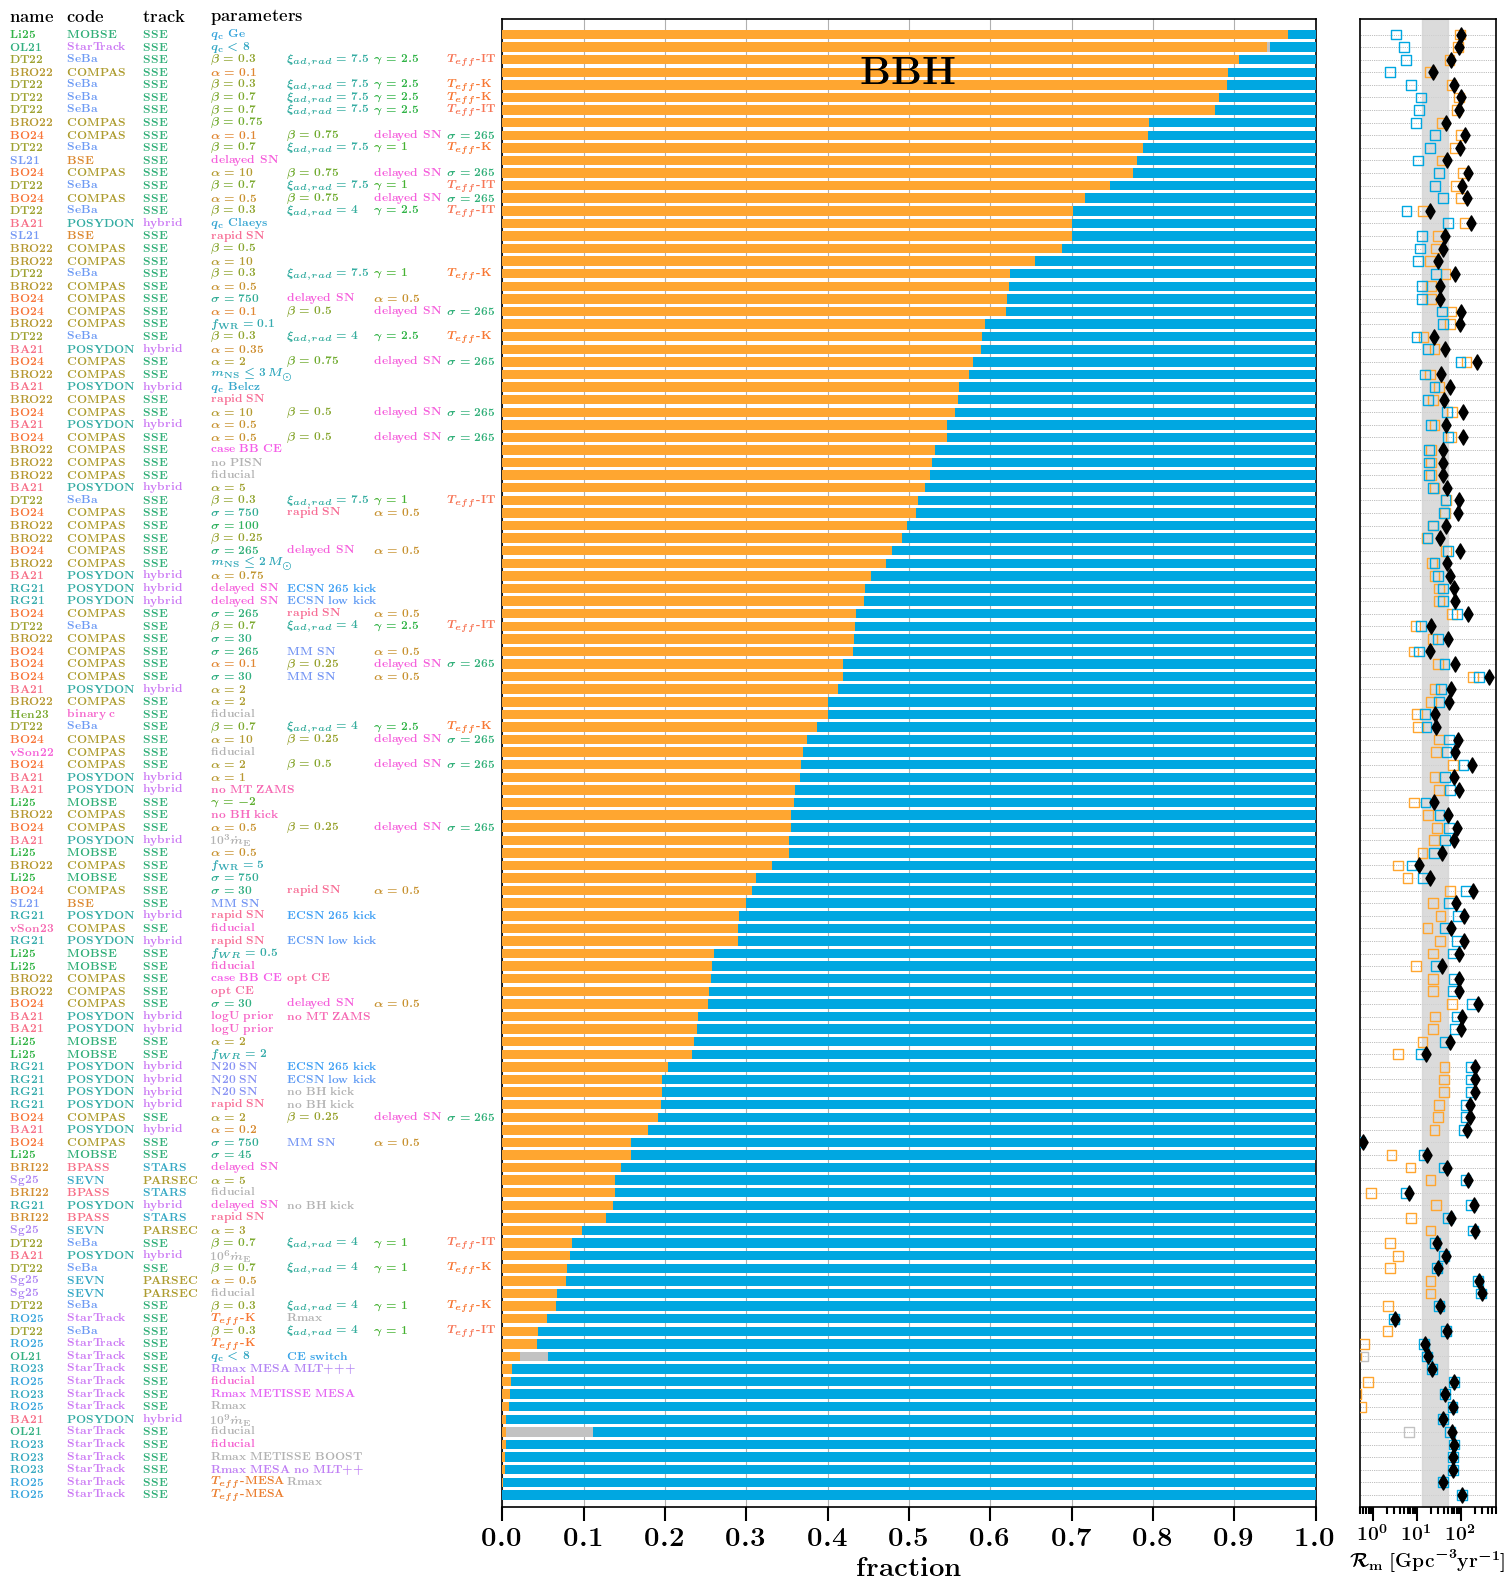

path /Users/floorbroekgaarden/Projects/GitHub/Rates_of_Formation_Channels/fc_data/Data_formation_channels_intrinsic/simulation_specs.csv


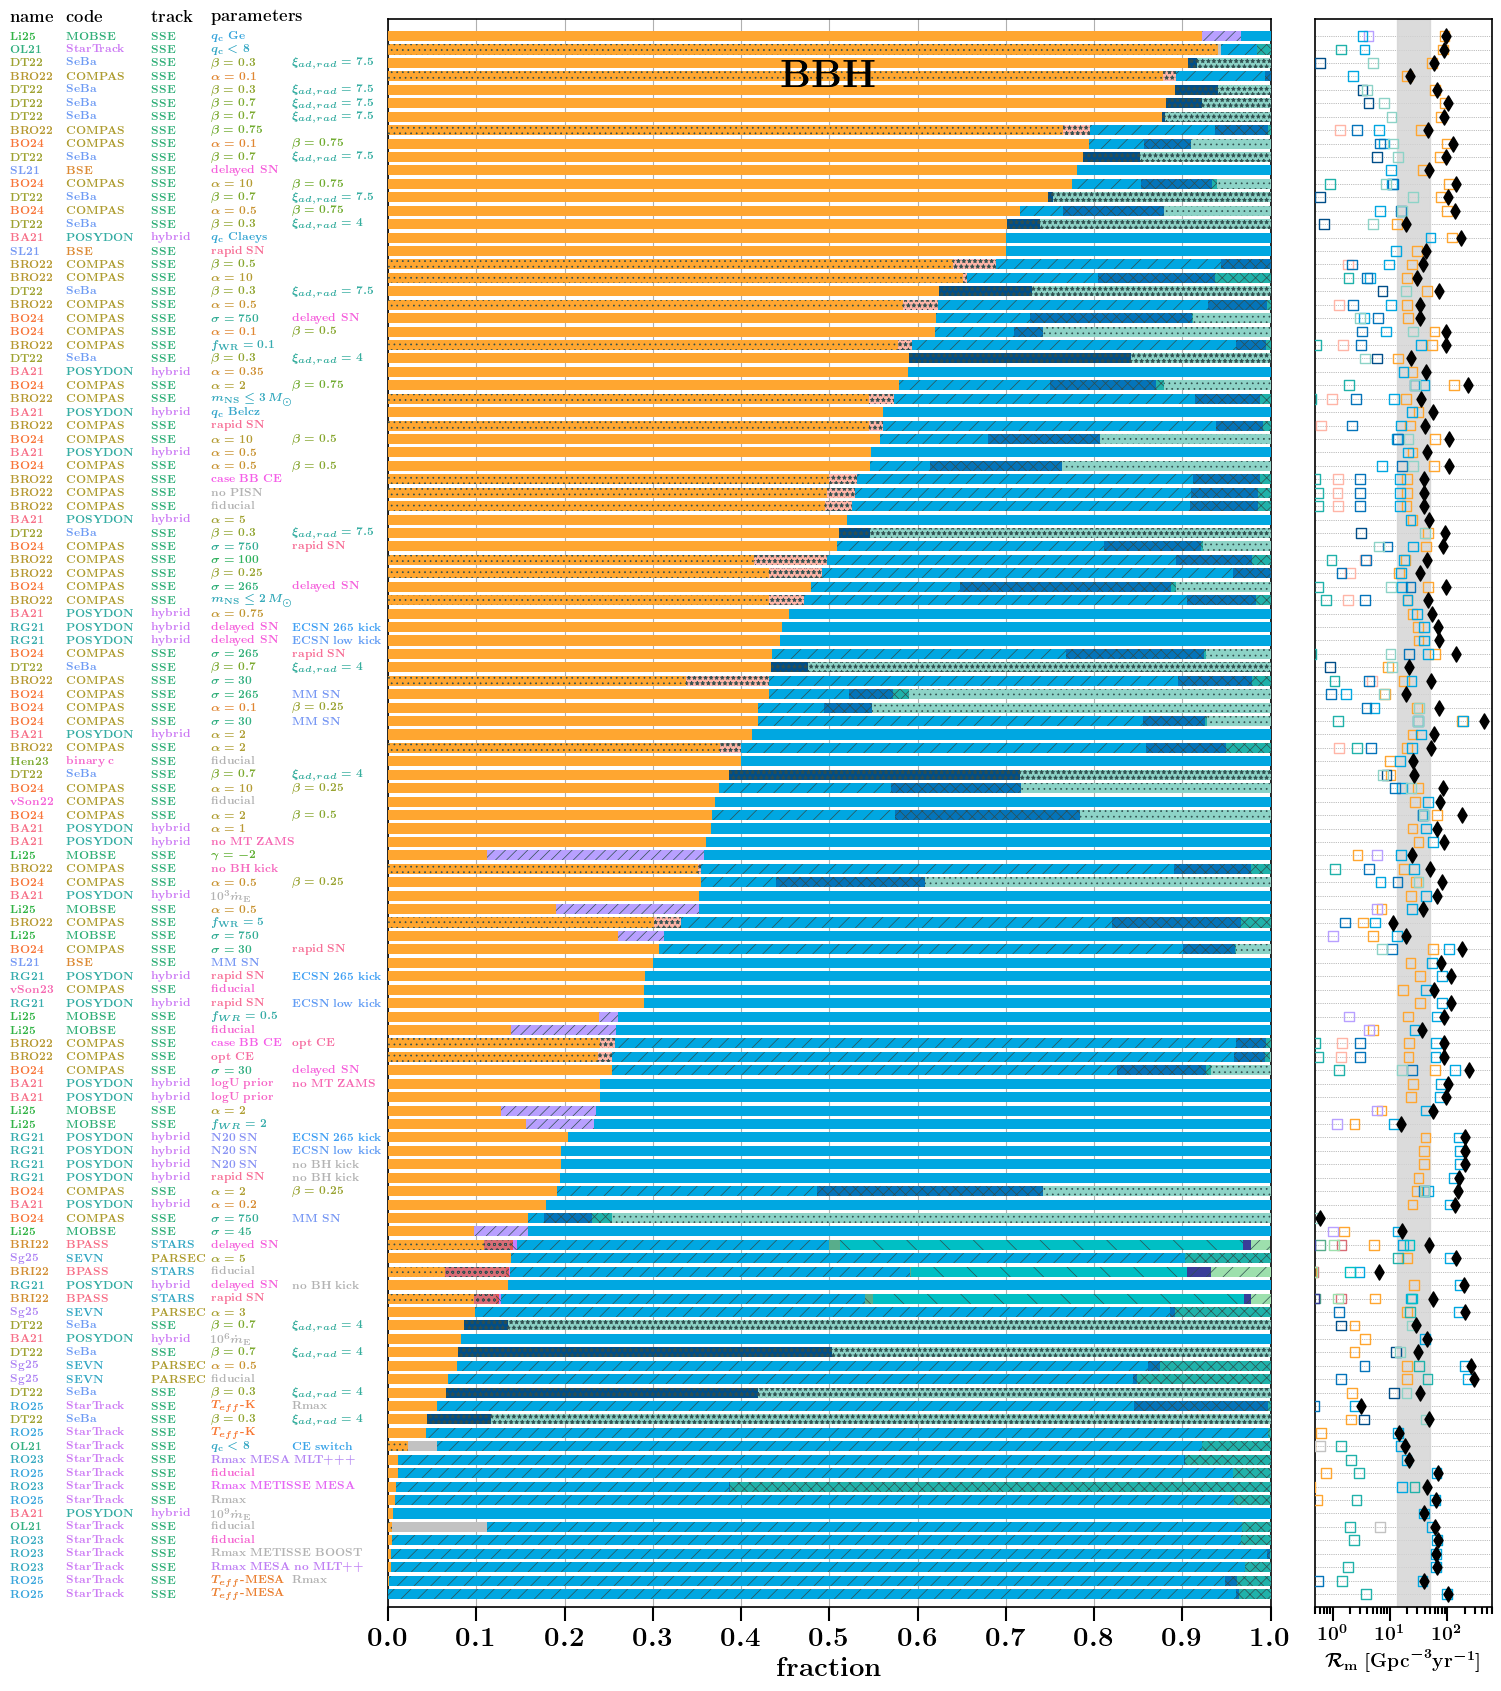

(<Figure size 1500x1700 with 3 Axes>,
 array([<Axes: >, <Axes: xlabel='$\\textbf{fraction}$'>,
        <Axes: xlabel='$\\mathcal{R}_{\\rm{m}} \\ [\\rm{Gpc}^{-3} \\rm{yr}^{-1}] $'>],
       dtype=object))

In [4]:
plot_formation_channel_contributions(
    path_to_file=path_to_file,
    DCOlabel = 'BH-BH',
    fc_key = "CE_simple" ,
    sort_header = "fraction without common envelope",
    save_path = path_to_save_fig + "Fig3_formation_channels_BH-BH_simple_specs.pdf",
    fig_formtype='emph_specs',    
    )



# plot only CE or not CE 
# plot_formation_channel_contributions(
#     path_to_file=path_to_file,
#     DCOlabel = 'BH-BH',
#     fc_key = "CE_simple" ,
#     sort_header = "fraction without common envelope",
#     save_path = path_to_save_fig + "Fig3_formation_channels_BH-BH_simple.pdf"
#     )


# plot detailed formation channels CE 
plot_formation_channel_contributions(
    path_to_file=path_to_file,
    DCOlabel = 'BH-BH',
    fc_key = "CE_detailed" ,
    sort_header = "fraction without common envelope",
    save_path = path_to_save_fig + "Fig3_formation_channels_BH-BH_detailed.pdf"
    )



# BH-NS mergers

path /Users/floorbroekgaarden/Projects/GitHub/Rates_of_Formation_Channels/fc_data/Data_formation_channels_intrinsic/simulation_specs.csv


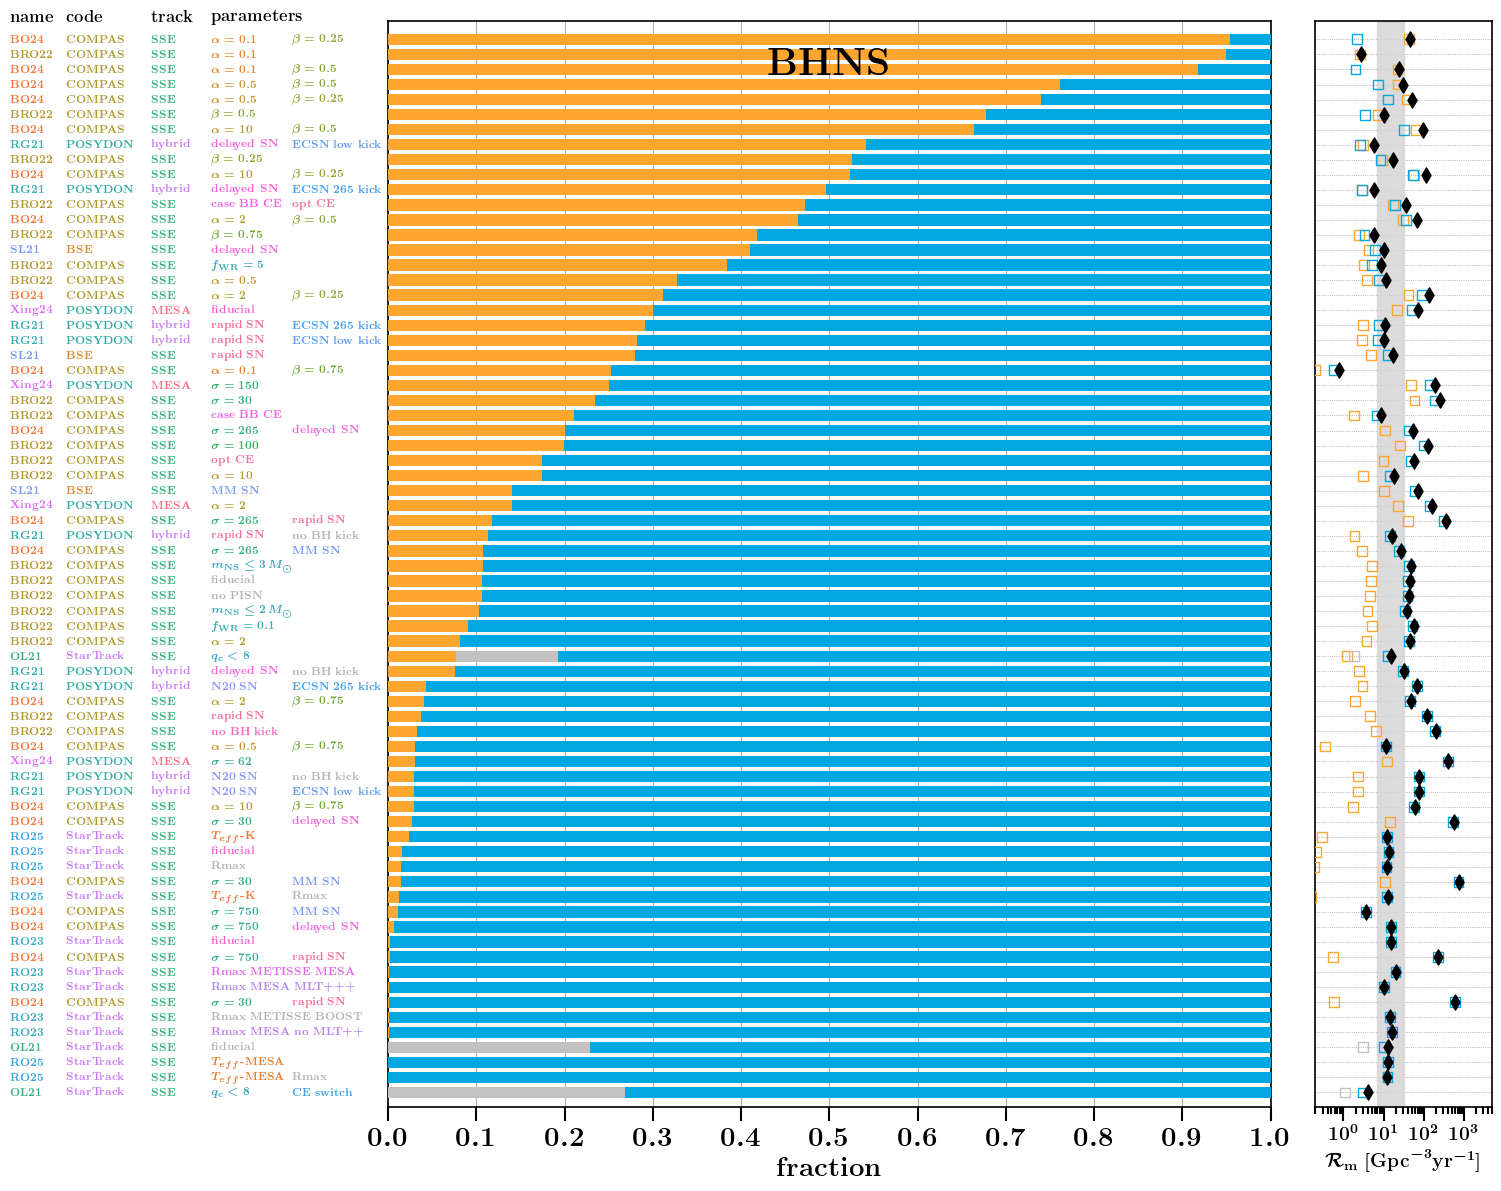

path /Users/floorbroekgaarden/Projects/GitHub/Rates_of_Formation_Channels/fc_data/Data_formation_channels_intrinsic/simulation_specs.csv


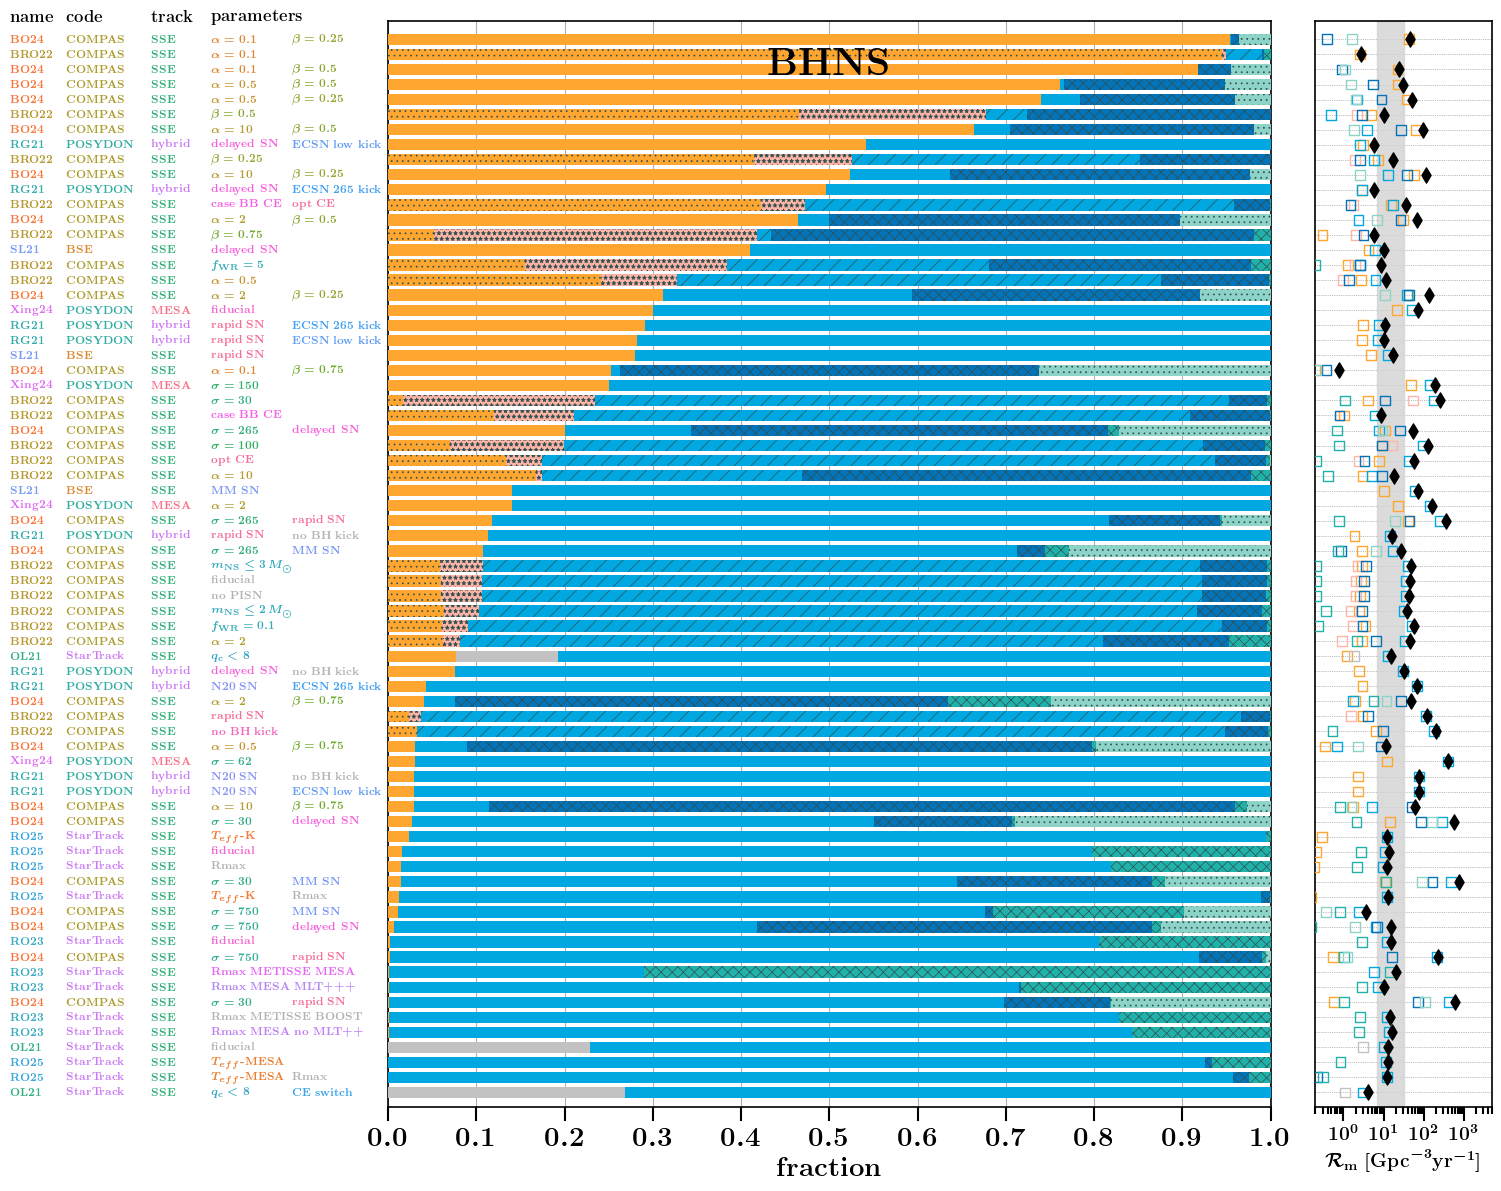

(<Figure size 1500x1200 with 3 Axes>,
 array([<Axes: >, <Axes: xlabel='$\\textbf{fraction}$'>,
        <Axes: xlabel='$\\mathcal{R}_{\\rm{m}} \\ [\\rm{Gpc}^{-3} \\rm{yr}^{-1}] $'>],
       dtype=object))

In [5]:



# plot only CE or not CE 
fig, axes = plot_formation_channel_contributions(
    path_to_file=path_to_file,
    DCOlabel = 'BH-NS',
    fc_key = "CE_simple" ,
    sort_header = "fraction without common envelope",
    save_path = path_to_save_fig + "Fig4_formation_channels_BH-NS_simple.pdf"
    )


# plot detailed formation channels CE 
plot_formation_channel_contributions(
    path_to_file=path_to_file,
    DCOlabel = 'BH-NS',
    fc_key = "CE_detailed" ,
    sort_header = "fraction without common envelope",
    save_path = path_to_save_fig + "Fig4_formation_channels_BH-NS_detailed.pdf"
    )






# NS-NS mergers 

path /Users/floorbroekgaarden/Projects/GitHub/Rates_of_Formation_Channels/fc_data/Data_formation_channels_intrinsic/simulation_specs.csv


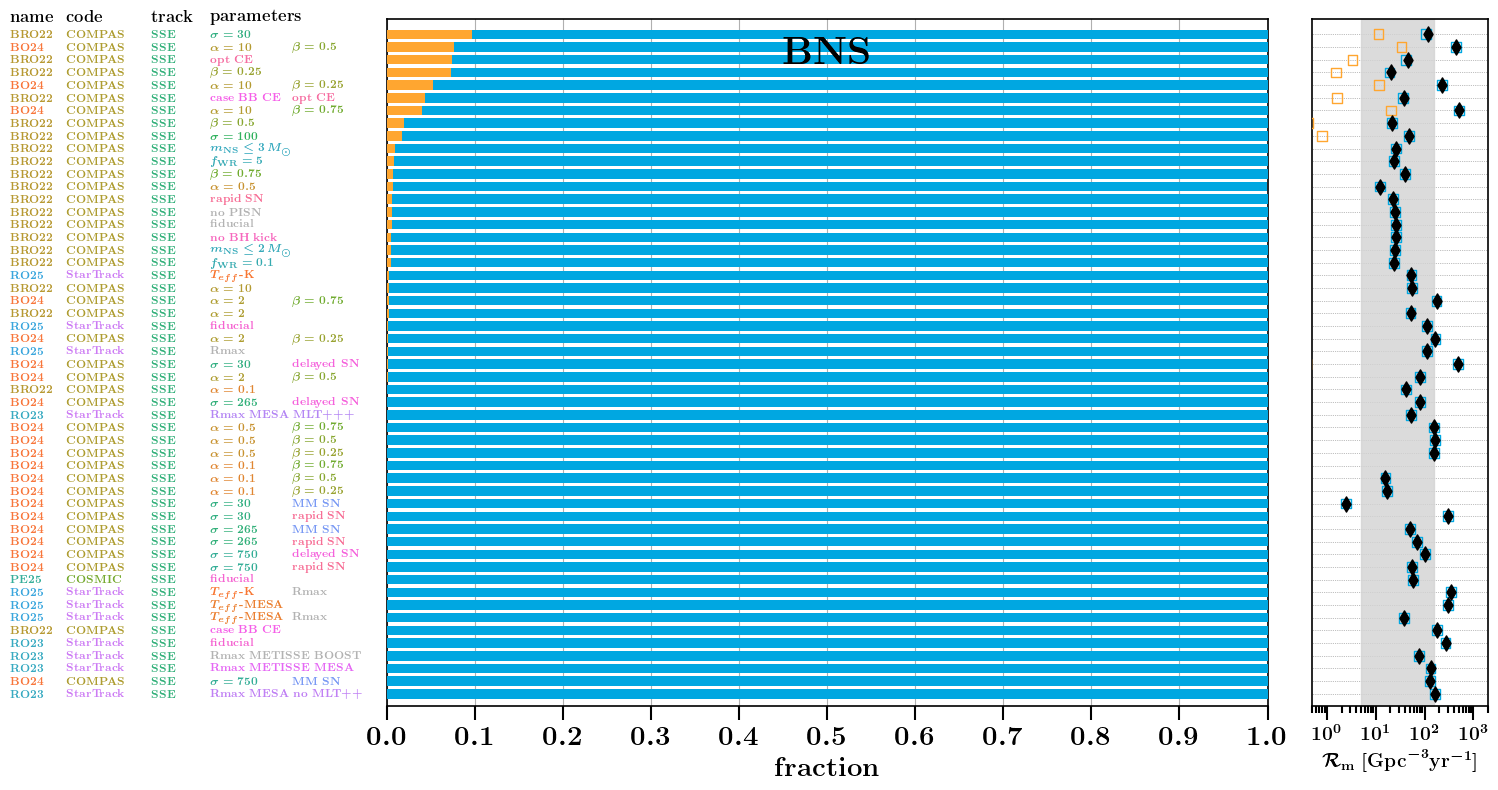

path /Users/floorbroekgaarden/Projects/GitHub/Rates_of_Formation_Channels/fc_data/Data_formation_channels_intrinsic/simulation_specs.csv


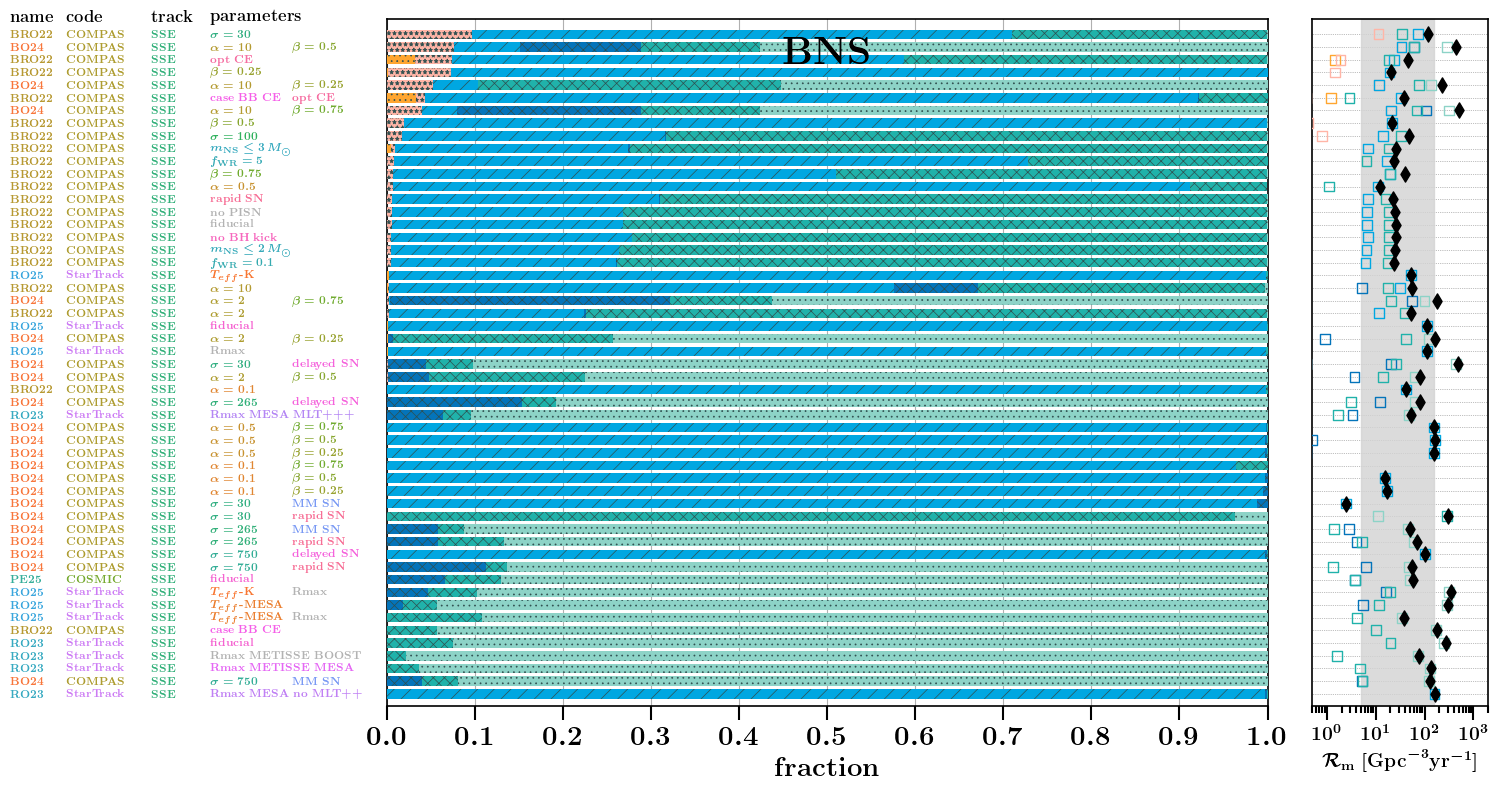

(<Figure size 1500x800 with 3 Axes>,
 array([<Axes: >, <Axes: xlabel='$\\textbf{fraction}$'>,
        <Axes: xlabel='$\\mathcal{R}_{\\rm{m}} \\ [\\rm{Gpc}^{-3} \\rm{yr}^{-1}] $'>],
       dtype=object))

In [6]:


# ---  plot setup ---

# plot only CE or not CE 
fig, axes = plot_formation_channel_contributions(
    path_to_file=path_to_file,
    DCOlabel = 'NS-NS',
    fc_key = "CE_simple" ,
    sort_header = "fraction without common envelope",
    save_path = path_to_save_fig + "Fig5_formation_channels_NS-NS_simple.pdf"
    )


# plot detailed formation channels CE 
plot_formation_channel_contributions(
    path_to_file=path_to_file,
    DCOlabel = 'NS-NS',
    fc_key = "CE_detailed" ,
    sort_header = "fraction without common envelope",
    save_path = path_to_save_fig + "Fig5_formation_channels_NS-NS_detailed.pdf"
    )





# Simulation Properties 


path /Users/floorbroekgaarden/Projects/GitHub/Rates_of_Formation_Channels/fc_data/Data_formation_channels_intrinsic/simulation_specs.csv


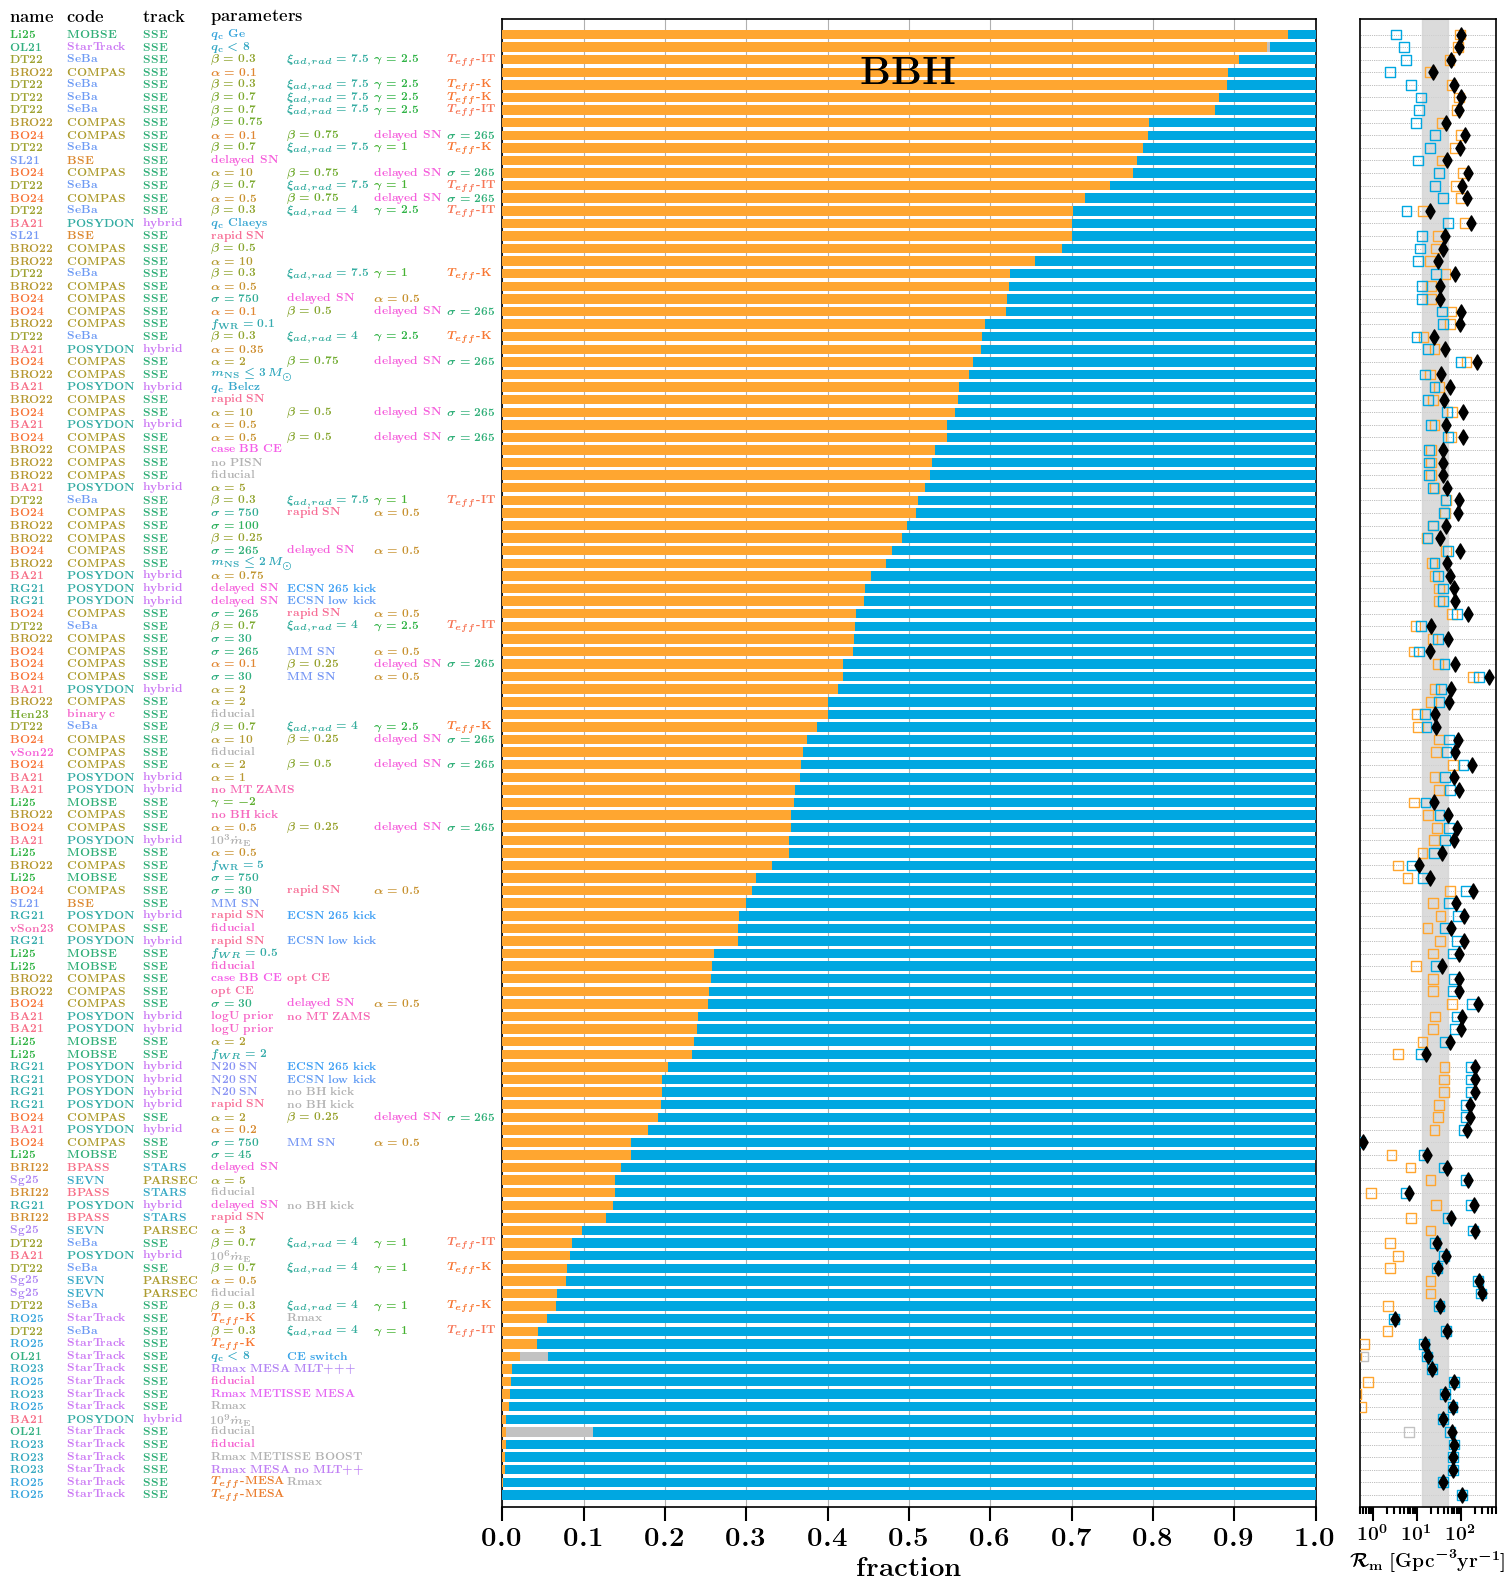

In [7]:


# --- File and plot setup ---

# plot only CE or not CE 
fig, axes = plot_formation_channel_contributions(
    path_to_file=path_to_file,
    DCOlabel = 'BH-BH',
    fc_key = "CE_simple" ,
    sort_header = "fraction without common envelope",
    save_path = path_to_save_fig + "extra_formation_channels_BH-BH_simple_specs.pdf",
    fig_formtype='emph_specs'
    )


# # plot detailed formation channels CE 
# plot_formation_channel_contributions(
#     path_to_file=path_to_file,
#     DCOlabel = 'BH-BH',
#     fc_key = "CE_detailed" ,
#     sort_header = "fraction without common envelope",
#     save_path = "formation_channels_BH-NS_detailed_specs.pdf"
#     )




# plot the legend



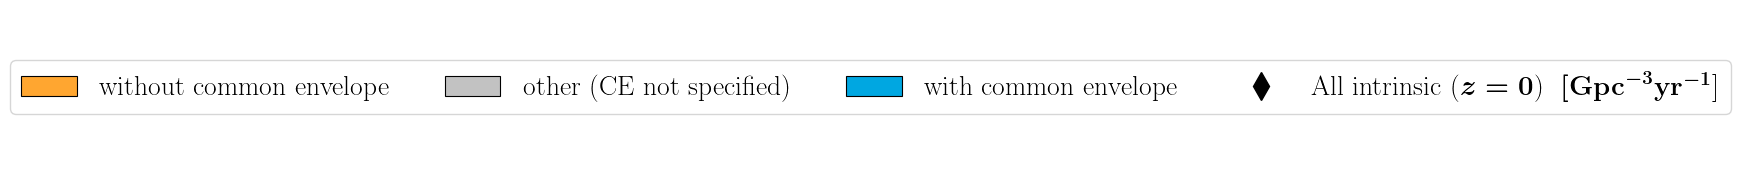

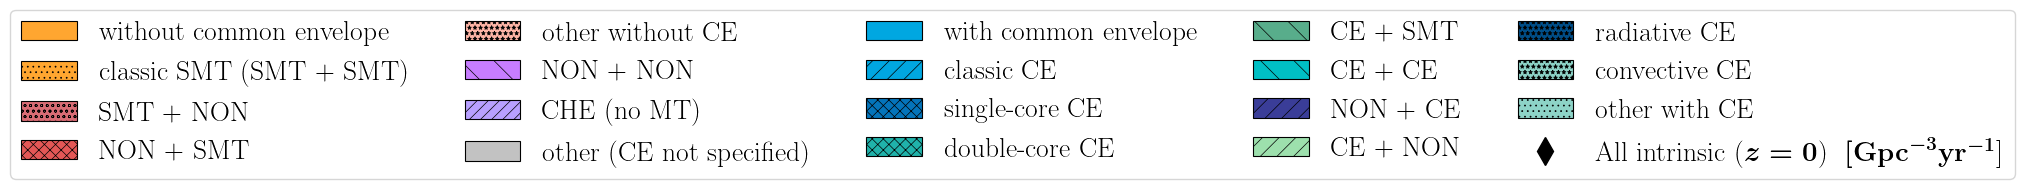

In [8]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D
import matplotlib as mpl

def plot_fc_legend(fc_key="CE_simple", include_total=True, path_to_save_fig='path/to/figures/'):
    """
    Create a plot legend for the specified formation channel group.
    
    Parameters
    ----------
    fc_key : str
        Key in fc_dict (e.g., "CE_simple" or "CE_detailed").
    include_total : bool
        If True, add the 'total' diamond marker to the legend.
    """
    mpl.rcParams["text.usetex"] = True
    
    fc_dict = obtain_fc_dict()
    
    if fc_key not in fc_dict:
        raise ValueError(f"fc_key '{fc_key}' not found in fc_dict. "
                         f"Available keys: {list(fc_dict.keys())}")
    
    group = fc_dict[fc_key]
    handles, labels = [], []
    
    # Add bar patches for channels
    if "channels" in group:  
        for ch in group["channels"]:
            patch = mpatches.Patch(
                facecolor=ch["color"], 
                hatch=ch["hatch"] if ch["hatch"] else "",
                edgecolor="black",
                linewidth=0.8
            )
            handles.append(patch)
            labels.append(ch.get("label", ch["name"]))
    else:  
        # single entry (unlikely for CE_simple/detailed but valid for total-only plots)
        ch = group
        patch = mpatches.Patch(
            facecolor=ch["color"], 
            hatch=ch["hatch"] if ch["hatch"] else "",
            edgecolor="black",
            linewidth=0.8
        )
        handles.append(patch)
        labels.append(ch.get("label", ch["name"]))
    
    # Add the total marker if requested
    if include_total:
        total_ch = fc_dict["total"]
        total_marker = Line2D(
            [0], [0],
            marker="d", color=total_ch["color"], markersize=14,
            linestyle="None", markeredgecolor="black"
        )
        handles.append(total_marker)
        labels.append(total_ch.get("label", total_ch["name"]))
    
    # Dummy plot for legend only
    fig, ax = plt.subplots(figsize=(7, 2))
    ax.axis("off")
    legend = ax.legend(handles, labels, loc="center", frameon=True, ncol=5, fontsize=20)
    save_path = path_to_save_fig + '/Fig3_' + fc_key + '_lgd.pdf'
    fig.savefig(save_path, format='pdf', bbox_inches='tight')
    plt.show()
    
    
plot_fc_legend("CE_simple", path_to_save_fig=path_to_save_fig)
plot_fc_legend("CE_detailed", path_to_save_fig=path_to_save_fig)


